# Clustering and Representation Dependence
## When changing the feature space changes the groups

**Practical 9 — core approximately 65–70 minutes, optional extension up to 85 minutes**

In Practical 8, we reduced 13 chemical measurements to a smaller number of coordinates using PCA. We now ask a different question:

> If we group observations by numerical similarity, what determines which observations belong together?

We will continue with the **Wine dataset** so that the data itself is familiar. The main experiment is to change the *representation* while keeping the clustering algorithm fixed.

```text
chemical measurements
         ↓
raw / standardized / PCA coordinates
         ↓
       K-means
         ↓
  different partitions?
```

We will then contrast K-means with **DBSCAN**, which uses a different notion of a cluster.

### Learning outcomes

After this session you should be able to:

1. distinguish cluster assignments from known class labels
2. explain the objective and assumptions of K-means
3. show why standardization changes Euclidean clustering
4. read inertia, silhouette and cluster sizes without treating them as proof of truth
5. compare clustering results in original and PCA-reduced feature spaces
6. explain DBSCAN's `eps`, `min_samples` and noise label
7. use external labels only for **evaluation**, not to fit or select an unsupervised partition
8. justify a clustering result with evidence rather than a visually pleasing plot

### Requirements

`numpy`, `pandas`, `matplotlib`, `scikit-learn`. No internet or external data files are required.

### Session plan

| Time | Part | Main question |
|---|---|---|
| 0–10 min | 1. Data and geometry | What exactly are we grouping? |
| 10–30 min | 2. K-means | What changes when we scale the features? |
| 30–45 min | 3. PCA and clustering | Are groups preserved by projection? |
| 45–60 min | 4. DBSCAN and evaluation | What if “cluster” means a dense region? |
| 60–70 min | 5. Exit challenge | Which result would we trust, and why? |
| 70–85 min | 6. Optional | Why two curved groups break K-means |

The **core is Parts 1–5**. The optional example can be left for independent work.

---
## 0. Environment

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import __version__ as sklearn_version
from sklearn.datasets import load_wine, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
)

print("Python:      ", sys.version.split()[0])
print("NumPy:       ", np.__version__)
print("pandas:      ", pd.__version__)
print("scikit-learn:", sklearn_version)

Python:       3.13.5
NumPy:        2.3.5
pandas:       2.2.3
scikit-learn: 1.8.0


---
## 1. Same data, a new task

We use the [UCI Wine dataset](https://archive.ics.uci.edu/dataset/109/wine), distributed with
[`sklearn.datasets.load_wine`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html): **178 observations**, **13 numerical chemical measurements**, **three known cultivars**.

Practical 8 used these known labels for LDA. **Today we must not use them to fit clustering models.**

A known cultivar is an independently supplied category. A cluster is a group formed from the numerical feature space. They need not coincide.

The label array is saved separately and will only reappear in the evaluation section.

In [2]:
wine = load_wine(as_frame=True)

X = wine.data.copy()               # chemical measurements only
reference_labels = wine.target.copy()  # do not use to fit clusters

print("Feature matrix:", X.shape)
print("Missing values:", int(X.isna().sum().sum()))
print("Known classes (evaluation only):", reference_labels.nunique())

display(X.head(3))

Feature matrix: (178, 13)
Missing values: 0
Known classes (evaluation only): 3


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0


### Units determine distance

Recall the unusually different scales from Practical 8. In raw Euclidean distance, a numerical change of `100` in one column can outweigh a meaningful change of `0.5` in another.

Standardization does **not** merely clean the table. It changes the metric geometry that K-means sees.

In [3]:
feature_spread = (
    X.std()
    .sort_values(ascending=False)
    .rename("standard_deviation")
    .to_frame()
)

display(feature_spread.head(5))
display(feature_spread.tail(5))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

assert X_scaled.shape == X.shape
assert np.isfinite(X_scaled).all()

,standard_deviation
proline,314.907474
magnesium,14.282484
alcalinity_of_ash,3.339564
color_intensity,2.318286
malic_acid,1.117146


,standard_deviation
total_phenols,0.625851
proanthocyanins,0.572359
ash,0.274344
hue,0.228572
nonflavanoid_phenols,0.124453


---
## 2. K-means — compact groups around centroids

For a chosen number of groups \(k\), K-means minimizes within-cluster squared Euclidean distances:

\[
\sum_{c=1}^{k}\sum_{i\in C_c}\lVert x_i-\mu_c\rVert^2.
\]

Lloyd's algorithm alternates between assigning observations to their nearest centroid and updating each centroid.

K-means tends to favour **compact, centroid-representable groups**. It will return the requested number of clusters even if the data have no natural separation at that resolution.

We'll use `k=3` as a **fixed benchmark setting**. The dataset happens to have three documented cultivars, but that does not establish three natural clusters. No class labels enter model fitting or silhouette-based comparisons.

In [4]:
k = 3

raw_model = KMeans(n_clusters=k, random_state=42, n_init=10)
scaled_model = KMeans(n_clusters=k, random_state=42, n_init=10)

raw_clusters = raw_model.fit_predict(X)
scaled_clusters = scaled_model.fit_predict(X_scaled)

cluster_sizes = pd.DataFrame({
    "raw units": pd.Series(raw_clusters).value_counts().sort_index(),
    "standardized": pd.Series(scaled_clusters).value_counts().sort_index(),
}).rename_axis("cluster_id")

display(cluster_sizes)

,raw units,standardized
cluster_id,,
0,62,65
1,47,51
2,69,62


The integer cluster IDs are **arbitrary identifiers**, not rankings. Cluster `0` in one fit does not necessarily correspond to cluster `0` in another.

### Visual comparison in one common coordinate system

We can plot both partitions using the **same 2D PCA coordinates**. That keeps the figure's axes fixed while changing only the assigned cluster colours.

Note the distinction: K-means was fitted in **13D raw** or **13D standardized** space; PCA is used **only to display** their assignments here.

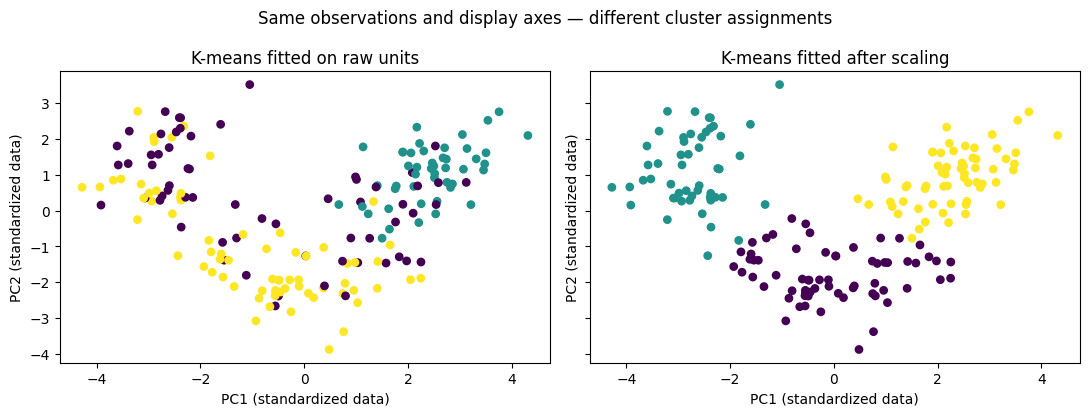

In [5]:
visual_pca = PCA(n_components=2)
X_plot = visual_pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)

for ax, labels, title in zip(
    axes,
    [raw_clusters, scaled_clusters],
    ["K-means fitted on raw units", "K-means fitted after scaling"],
):
    ax.scatter(X_plot[:, 0], X_plot[:, 1], c=labels, cmap="viridis", s=28)
    ax.set(title=title, xlabel="PC1 (standardized data)", ylabel="PC2 (standardized data)")

fig.suptitle("Same observations and display axes — different cluster assignments")
plt.tight_layout()
plt.show()

### 2.1 Inertia and silhouette

K-means reports **inertia**, the sum of squared distances to assigned centroids. Lower inertia at the same \(k\) means a better fit *to the objective in that specific feature space*.

**Do not compare inertia values across raw and standardized spaces**: the distances have different units/scales.

The **silhouette coefficient** compares an observation's average within-cluster distance with its nearest alternative cluster. It is useful for inspecting compactness and separation, but it also depends on the representation and geometry.

In [6]:
raw_sil = silhouette_score(X, raw_clusters)
scaled_sil = silhouette_score(X_scaled, scaled_clusters)

print(f"Raw space:          silhouette = {raw_sil:.3f}")
print(f"Standardized space: silhouette = {scaled_sil:.3f}")
print()
print(f"Raw-space inertia:          {raw_model.inertia_:.1f}  (raw squared units)")
print(f"Standardized-space inertia: {scaled_model.inertia_:.1f}  (scaled squared units)")

Raw space:          silhouette = 0.571
Standardized space: silhouette = 0.285

Raw-space inertia:          2370689.7  (raw squared units)
Standardized-space inertia: 1277.9  (scaled squared units)


A higher silhouette here does **not** imply a more meaningful scientific grouping. It tells us which grouping better fits one particular distance-based criterion.

### 2.2 Choosing `k` is a modelling decision

Let's inspect how the silhouette behaves for several values of `k` **within the standardized space**. That is a valid same-geometry comparison.

,silhouette,inertia,smallest_cluster
k,,,
2,0.259,1658.759,87
3,0.285,1277.928,51
4,0.260,1175.428,29
5,0.202,1109.513,26
6,0.237,1046.002,5


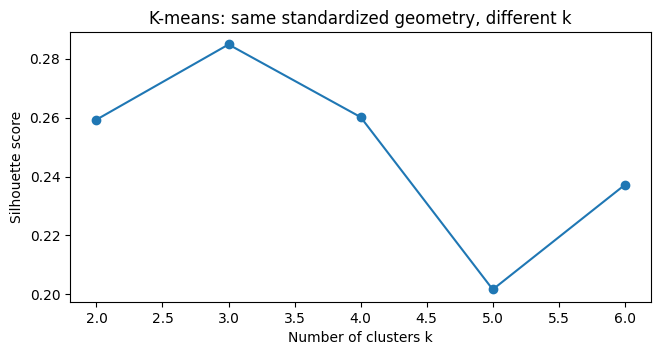

In [7]:
rows = []
for candidate_k in range(2, 7):
    model = KMeans(n_clusters=candidate_k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    rows.append({
        "k": candidate_k,
        "silhouette": silhouette_score(X_scaled, labels),
        "inertia": model.inertia_,
        "smallest_cluster": pd.Series(labels).value_counts().min(),
    })

k_results = pd.DataFrame(rows).set_index("k")
display(k_results.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(k_results.index, k_results["silhouette"], marker="o")
ax.set(xlabel="Number of clusters k", ylabel="Silhouette score",
       title="K-means: same standardized geometry, different k")
plt.show()

### Exercise A — one more partition

Compare `k=3` with `k=4` **on the standardized 13D features**.

Report the silhouette values and cluster-size distributions. Is there enough evidence to say that one partition is *scientifically correct*? Explain in two sentences.

In [8]:
# Your solution starts here.

---
## 3. Clustering in a PCA representation

PCA changes the data coordinates. With fewer than 13 components, the representation is also lossy.

Here we fit **K-means with the same `k=3`** on:

- all 13 standardized features
- the first 2 PCA scores
- the first 5 PCA scores

We will compare the partitions, not just the appearance of their 2D plots.

In [9]:
pca_full = PCA().fit(X_scaled)
X_pca2 = PCA(n_components=2).fit_transform(X_scaled)
X_pca5 = PCA(n_components=5).fit_transform(X_scaled)

labels_pca2 = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_pca2)
labels_pca5 = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_pca5)

comparison = pd.DataFrame([
    {
        "representation": "13D standardized",
        "dimensions": 13,
        "variance_retained_pct": 100.0,
        "silhouette_in_its_space": silhouette_score(X_scaled, scaled_clusters),
        "agreement_with_13D_ARI": 1.0,
    },
    {
        "representation": "2D PCA scores",
        "dimensions": 2,
        "variance_retained_pct": 100 * pca_full.explained_variance_ratio_[:2].sum(),
        "silhouette_in_its_space": silhouette_score(X_pca2, labels_pca2),
        "agreement_with_13D_ARI": adjusted_rand_score(scaled_clusters, labels_pca2),
    },
    {
        "representation": "5D PCA scores",
        "dimensions": 5,
        "variance_retained_pct": 100 * pca_full.explained_variance_ratio_[:5].sum(),
        "silhouette_in_its_space": silhouette_score(X_pca5, labels_pca5),
        "agreement_with_13D_ARI": adjusted_rand_score(scaled_clusters, labels_pca5),
    },
])

display(comparison.round(3))

,representation,dimensions,variance_retained_pct,silhouette_in_its_space,agreement_with_13D_ARI
0,13D standardized,13,100.000,0.285,1.000
1,2D PCA scores,2,55.406,0.561,0.932
2,5D PCA scores,5,80.162,0.369,1.000


**Adjusted Rand index (ARI)** compares *two partitions of the same observations*, accounting for chance agreement. Here we compare cluster assignments with one another — **not** with the known wine labels.

The silhouette values above use **different feature spaces**. Their numerical difference is not a controlled comparison of cluster quality because the underlying distances have changed.

Now compare the 13D and 2D assignments on the same display axes.

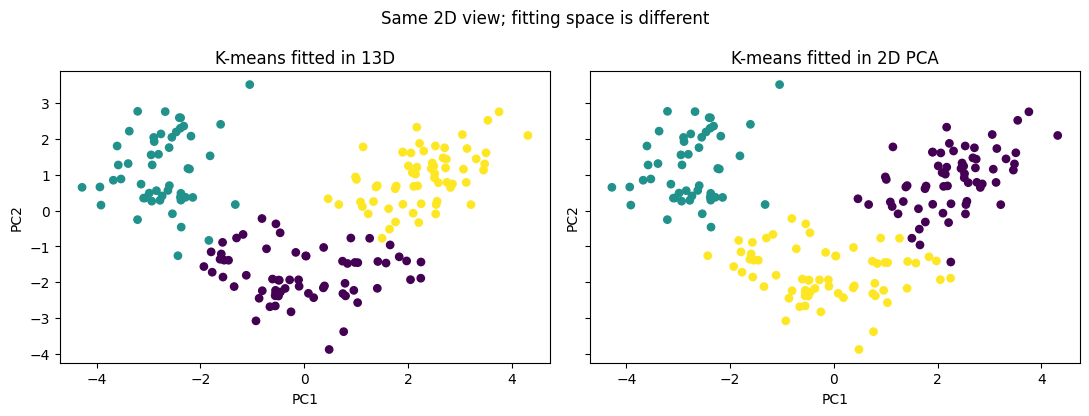

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)

for ax, labels, title in zip(
    axes,
    [scaled_clusters, labels_pca2],
    ["K-means fitted in 13D", "K-means fitted in 2D PCA"],
):
    ax.scatter(X_pca2[:, 0], X_pca2[:, 1], c=labels, cmap="viridis", s=28)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")

fig.suptitle("Same 2D view; fitting space is different")
plt.tight_layout()
plt.show()

### Exercise B — does keeping more components help?

Using the table above, describe whether the 5D PCA partition agrees more closely with the 13D partition than the 2D partition does.

Do **not** infer that the higher-dimensional representation is universally better. State what ARI is measuring **in this comparison**.

**Your response:**

*Replace with two or three sentences.*

---
## 4. Density-based clustering: DBSCAN

K-means always assigns an observation to one of \(k\) groups. DBSCAN uses a different idea:

- an observation is a **core point** when its radius-\(\varepsilon\) neighbourhood contains at least `min_samples` observations (including itself)
- nearby core points form density-connected groups
- observations that do not belong to a discovered group may be labelled **noise** (`-1`)

`eps` is a *distance in the chosen feature space*, so it must be reconsidered if the representation or scaling changes.

We'll run DBSCAN **in the same 2D PCA space** at two resolutions.

In [11]:
def dbscan_summary(values, eps, min_samples=5):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(values)
    n_clusters = len(set(labels) - {-1})
    n_noise = int((labels == -1).sum())
    return labels, n_clusters, n_noise

parameters = [0.6, 1.0]
dbscan_runs = {}

for eps in parameters:
    labels, count, n_noise = dbscan_summary(X_pca2, eps=eps)
    dbscan_runs[eps] = labels
    print(f"eps={eps:.1f}: clusters={count}, noise={n_noise}/{len(labels)}")

eps=0.6: clusters=2, noise=16/178
eps=1.0: clusters=1, noise=2/178


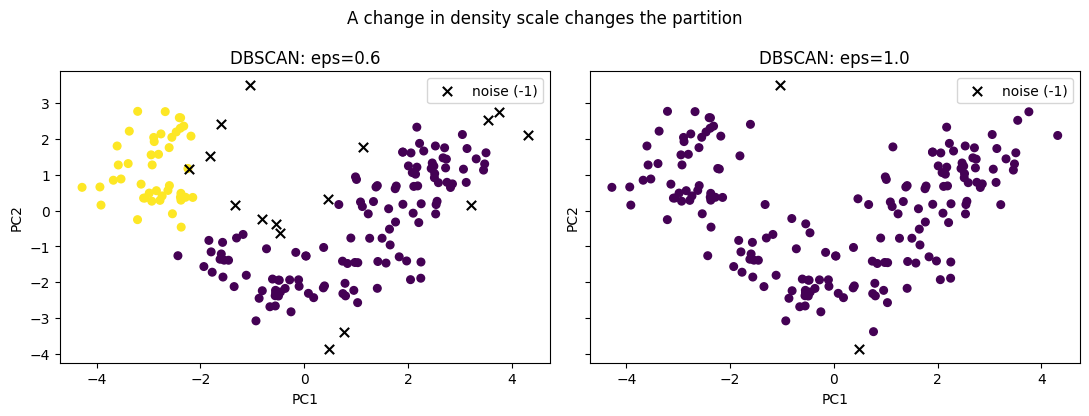

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)

for ax, eps in zip(axes, parameters):
    labels = dbscan_runs[eps]
    is_noise = labels == -1

    ax.scatter(X_pca2[~is_noise, 0], X_pca2[~is_noise, 1],
               c=labels[~is_noise], cmap="viridis", s=30)
    ax.scatter(X_pca2[is_noise, 0], X_pca2[is_noise, 1],
               c="black", marker="x", s=45, label="noise (-1)")

    ax.set(title=f"DBSCAN: eps={eps}", xlabel="PC1", ylabel="PC2")
    if is_noise.any():
        ax.legend()

fig.suptitle("A change in density scale changes the partition")
plt.tight_layout()
plt.show()

DBSCAN does not promise that the number of clusters will match K-means or the known cultivar count. For this dataset, some parameter choices may merge most observations into one cluster.

A high number of noise points is not automatically an error: the meaning depends on the task. Nor is every noise point a confirmed anomaly.

### 4.1 Validation: internal versus external evidence

We deliberately kept `reference_labels` out of model fitting. We can now use them for an **external diagnostic**: do discovered groups resemble the known cultivars?

ARI = 1 indicates identical partitions up to label renaming; around 0 indicates chance-level agreement under the adjusted baseline. It can be negative.

In [13]:
validation = pd.DataFrame([
    {
        "fit_space": "raw 13D",
        "silhouette": silhouette_score(X, raw_clusters),
        "ARI_vs_cultivar": adjusted_rand_score(reference_labels, raw_clusters),
    },
    {
        "fit_space": "standardized 13D",
        "silhouette": silhouette_score(X_scaled, scaled_clusters),
        "ARI_vs_cultivar": adjusted_rand_score(reference_labels, scaled_clusters),
    },
    {
        "fit_space": "PCA 2D",
        "silhouette": silhouette_score(X_pca2, labels_pca2),
        "ARI_vs_cultivar": adjusted_rand_score(reference_labels, labels_pca2),
    },
])

display(validation.set_index("fit_space").round(3))

,silhouette,ARI_vs_cultivar
fit_space,,
raw 13D,0.571,0.371
standardized 13D,0.285,0.897
PCA 2D,0.561,0.895


**Notice the tension:** the raw-space partition can score better on silhouette while agreeing much less with the known cultivars.

Neither metric is “wrong”. They answer different questions:

- silhouette: how compact and separated are groups **under these feature-space distances**?
- external ARI: how similar is the partition to **a particular independent categorization**?

We did **not** use cultivar labels to choose `k`, `eps`, scaling, or PCA dimensions. If we start tuning those settings against ARI, the labels become part of model selection and a new independent evaluation set would be needed for an unbiased final claim.

---
## 5. Exit challenge — what did we really discover?

A colleague says:

> “The clustering with the highest silhouette is objectively the best clustering of these wines.”

Use today's outputs to write **four short answers**:

1. Which model/representation has the highest silhouette among the **three configurations in the final validation table**?
2. Does that configuration also have the highest agreement with the cultivar labels? Give the two metrics.
3. Why is comparing silhouettes across differently scaled or reduced feature spaces potentially misleading?
4. If the goal were *exploration of chemical similarity*, what evidence besides a 2D scatterplot would you inspect before presenting groups as meaningful?

**Your response:**

*Replace this text with four concise answers supported by notebook outputs.*

---
## 6. Optional extension — when clusters are not round

Skip this section if the core practical has filled the class time.

Wine measurements are a real dataset, but they do not make every algorithmic assumption visually obvious. For this one controlled comparison, we will generate a **synthetic two-moons example** with a known geometry.

The question is not whether DBSCAN is universally superior. It is whether a density-connectivity objective can capture something that Euclidean-centroid partitioning cannot.

In [14]:
moon_X, moon_y = make_moons(n_samples=400, noise=0.07, random_state=7)
moon_scaled = StandardScaler().fit_transform(moon_X)

moon_kmeans = KMeans(n_clusters=2, random_state=7, n_init=10).fit_predict(moon_scaled)
moon_dbscan = DBSCAN(eps=0.22, min_samples=5).fit_predict(moon_scaled)

print("K-means groups:", len(np.unique(moon_kmeans)))
print("DBSCAN groups (excluding noise):", len(set(moon_dbscan) - {-1}))
print("DBSCAN noise points:", int((moon_dbscan == -1).sum()))

K-means groups: 2
DBSCAN groups (excluding noise): 2
DBSCAN noise points: 1


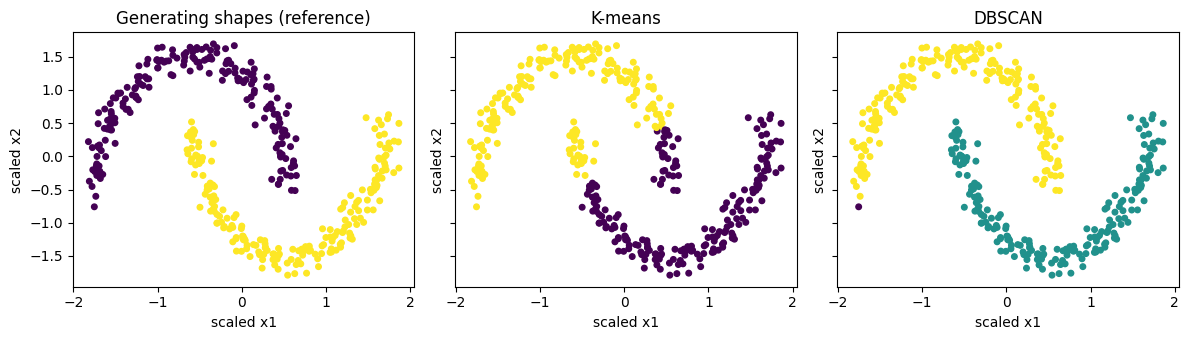

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True, sharey=True)

for ax, labels, title in zip(
    axes,
    [moon_y, moon_kmeans, moon_dbscan],
    ["Generating shapes (reference)", "K-means", "DBSCAN"],
):
    ax.scatter(moon_scaled[:, 0], moon_scaled[:, 1], c=labels, cmap="viridis", s=16)
    ax.set_title(title)
    ax.set_xlabel("scaled x1")
    ax.set_ylabel("scaled x2")

plt.tight_layout()
plt.show()

The first panel displays the **known generating groups** of this artificial example; the two clustering models did not receive them.

K-means partitions space into regions around centroids. DBSCAN can trace connected curved regions — **when its density scale is appropriate**. In datasets with large density variation or high dimensionality, the same DBSCAN settings may fail.

Try changing `eps` slightly. Does the result stay stable, or does one curve fragment or merge?

---
## Summary

### 1. Cluster assignments are model outputs, not discovered truths

K-means must return the requested number of groups. DBSCAN can instead return noise and a data-dependent number of groups. Each model carries assumptions about what a cluster should look like.

### 2. Representation comes first

Raw chemical units, standardized values, and PCA scores do not preserve exactly the same Euclidean distances. Changing them can change cluster membership even with the same algorithm.

### 3. Evaluation needs a question

Inertia, silhouette, ARI, cluster sizes and stability test different claims. A strong internal score is not proof of semantic meaning.

### 4. A 2D picture is not enough

We may display a 13D partition in two PCA coordinates, but the displayed geometry is not the geometry in which the clustering was fitted.

**Next:** Lab 03 — use dimensionality reduction and clustering together, with choices supported by evidence.

### Further reading

- *Clustering Algorithms: Definitions, Assumptions, and Limits* (course lecture notes)
- [scikit-learn: K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means)
- [scikit-learn: DBSCAN](https://scikit-learn.org/stable/modules/clustering.html#dbscan)
- [scikit-learn: Silhouette coefficient](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [scikit-learn: Adjusted Rand index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)
- [UCI Wine dataset](https://archive.ics.uci.edu/dataset/109/wine)